# Price model data preflight

This notebook runs read-only checks on the six Parquet sources in `DATA/CAR_DATA_FINAL`. It does not train models, remove rows, or edit source data. It writes reports and review candidates into a new ignored folder under `MODEL_OUTPUT/diagnostics/`.

The checks focus on the proposed used-listing benchmark: row keys, `is_new` scope, price and mileage, missingness, category cardinality, lowercase VIN linkage to NHTSA vPIC, and whether complaint/recall records can postdate an inferred listing observation date. Each row candidate is for human review only.

**Assumptions to review:** `listed_date + daysonmarket` is only a capture-date proxy, not a verified price timestamp. Peer-price comparisons use decoded `ModelYear`, `Make`, and `Model` while retaining `Trim` as its own column; they are review heuristics, not cohort aggregates. Missing source rows do not mean confirmed zero events.

## 1. Setup

Run from the project root. The script uses the project's existing Python requirements. If the notebook kernel starts elsewhere, the cell adds the project root to `sys.path`.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'MODELS' / 'price_data_diagnostics.py').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'MODELS' / 'price_data_diagnostics.py').is_file():
    raise FileNotFoundError('Open this notebook from the project checkout or set PROJECT_ROOT to the checkout path.')
sys.path.insert(0, str(PROJECT_ROOT))
from MODELS.price_data_diagnostics import run_diagnostics

DATA_DIR = PROJECT_ROOT / 'DATA' / 'CAR_DATA_FINAL'
OUTPUT_ROOT = PROJECT_ROOT / 'MODEL_OUTPUT' / 'diagnostics'
print(f'Source: {DATA_DIR}')
print(f'New reports will be written under: {OUTPUT_ROOT}')

Source: E:\DataScience_Capstone_Cars\DATA\CAR_DATA_FINAL
New reports will be written under: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\diagnostics


## 2. Run the diagnostics

The defaults reproduce the current review heuristics (`price < $500`, `price > $500,000`, mileage outside 0–1,000,000, or price at least 10 times the decoded year/make/model peer median when there are at least 20 rows). Change these only for a documented sensitivity check. No threshold changes eligibility or edits a value.

In [2]:
diagnostic_dir = run_diagnostics(
    data_dir=DATA_DIR,
    output_dir=None,  # Creates a new UTC-stamped directory.
    price_low=500,
    price_high=500_000,
    mileage_high=1_000_000,
    peer_ratio=10,
    peer_min_count=20,
    rare_count=20,
)
print(f'Reports: {diagnostic_dir}')

Reports: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\diagnostics\20260929T163158Z


## 3. Source inventory and listing scope

Check that required Parquet files exist, the Parquet row counts agree with `manifest.json`, and `is_new` resolves cleanly into new, used, or unknown. Compare distinct VIN and listing ID counts with row counts. The current benchmark assumes one source listing row per record; VIN is the vPIC join key, not a model predictor.

In [3]:
inventory = pd.read_csv(diagnostic_dir / 'source_inventory.csv')
manifest_check = pd.read_csv(diagnostic_dir / 'export_manifest_check.csv')
scope = pd.read_csv(diagnostic_dir / 'listing_scope_and_value_summary.csv')
keys = pd.read_csv(diagnostic_dir / 'listing_key_quality.csv')
display(inventory[['table', 'exists', 'rows', 'columns', 'size_mib']])
display(manifest_check.T)
display(scope)
display(keys)

,table,exists,rows,columns,size_mib
0,used_cars,True,3000000,59,1242.26
1,nhtsa_vpic_decodes,True,2999875,133,22.23
2,nhtsa_complaints,True,1390528,17,239.59
3,nhtsa_recalls,True,26993,20,1.95
4,nhtsa_safety_rating_values,True,8144,35,0.26
5,youtube_comments_sentiment,True,1981686,12,166.87


,0
manifest_present,True
export_created_at_utc,2026-09-28T15:05:49.614727+00:00
tables_with_count_mismatch,0
mismatch_details,[]
note,Manifest row counts are checked against the cu...


,vehicle_scope,rows,distinct_vins_including_null,null_vins,non_17_character_vins,null_listing_id,null_price,null_mileage,null_year,price_min,...,mileage_p50,mileage_p90,mileage_p99,mileage_max,nonpositive_price_rows,price_below_500_rows,price_above_500k_rows,negative_mileage_rows,zero_mileage_rows,mileage_above_1m_rows
0,new,1471021,1471021,0,0,0,0,128099,0,8866,...,5.0,23.0,4263.0,99999988.0,0,0,21,0,256894,8
1,used,1528979,1528979,0,3052,0,0,16288,0,165,...,41167.0,127830.0,209000.0,400000.0,0,86,87,0,3,0


,key,source_rows,null_key_rows,duplicate_key_values,rows_with_a_duplicate_key,duplicate_row_rate
0,vin,3000000,0,0,0,0.0
1,listing_id,3000000,0,0,0,0.0


## 4. Missingness and high-cardinality fields

Missingness is separated by new/used/unknown because blank condition fields have different meanings for new and used vehicles. Category counts compare raw distinct strings with case/whitespace-normalized levels and show how many rows fall into levels with at most 20 used listings. `major_options` is profiled for cardinality only because its structured combinations would create a very large rare-level table.

,vehicle_scope,feature,rows,missing_rows,missing_rate
0,new,owner_count,1471021,1470053,0.999342
1,new,theft_title,1471021,1424622,0.968458
2,new,fleet,1471021,1424622,0.968458
3,new,salvage,1471021,1424622,0.968458
4,new,frame_damaged,1471021,1424622,0.968458
5,new,has_accidents,1471021,1424622,0.968458
6,new,city_fuel_economy,1471021,251050,0.170664
7,new,highway_fuel_economy,1471021,251050,0.170664
8,new,listing_color,1471021,236123,0.160516
9,new,interior_color,1471021,144551,0.098266


,feature,used_nonmissing_rows,raw_distinct_levels,normalized_distinct_levels,levels_at_or_below_rare_count,rows_in_rare_levels,rare_count_threshold
0,major_options,1461052,191865,191865,NaN,NaN,NaN
1,interior_color,1528974,18412,15481,14182.0,37141.0,20.0
2,exterior_color,1528979,18460,14912,12753.0,38399.0,20.0
3,trim_name,1486896,8780,8736,5455.0,30726.0,20.0
4,model_name,1528979,1419,1418,568.0,3116.0,20.0
5,listing_color,1528979,15,15,0.0,0.0,20.0


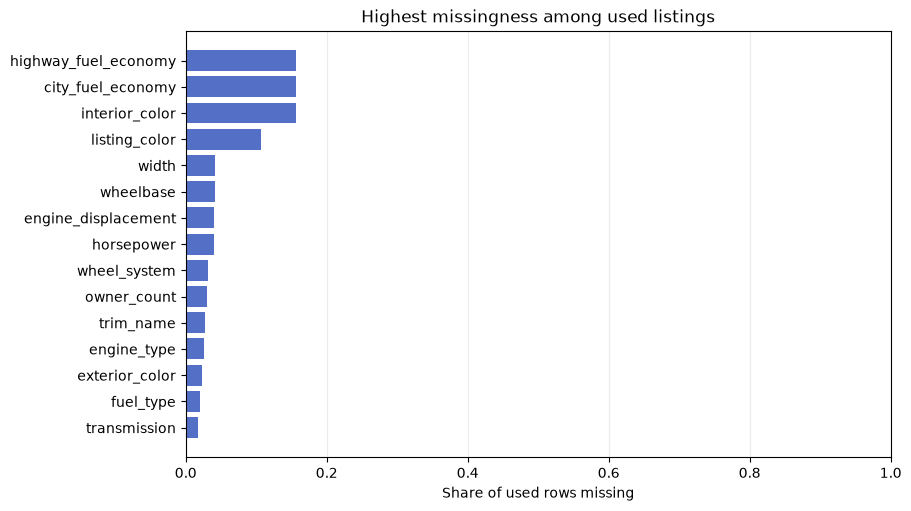

In [4]:
missingness = pd.read_csv(diagnostic_dir / 'base_feature_missingness.csv')
cardinality = pd.read_csv(diagnostic_dir / 'used_category_cardinality.csv')
display(missingness.sort_values(['vehicle_scope', 'missing_rate'], ascending=[True, False]).groupby('vehicle_scope').head(12))
display(cardinality)

if not missingness.empty:
    used_missing = missingness[missingness.vehicle_scope == 'used'].nlargest(15, 'missing_rate')
    fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
    ax.barh(used_missing.feature[::-1], used_missing.missing_rate[::-1], color='#5470C6')
    ax.set_title('Highest missingness among used listings')
    ax.set_xlabel('Share of used rows missing')
    ax.set_xlim(0, 1)
    ax.grid(axis='x', alpha=.25)
    plt.show()

## 5. VIN linkage and vehicle identity

Listings link to the lowercase `vin` field in vPIC. `vin_join_and_identity_summary.csv` should show no join row expansion and very high match coverage. Compare listing year/make/model disagreements with the separate decoded `ModelYear`, `Make`, `Model`, and `Trim` fields. A disagreement is a review signal: naming granularity can differ legitimately. Up to 500 used-row examples are saved separately.

In [5]:
join_summary = pd.read_csv(diagnostic_dir / 'vin_join_and_identity_summary.csv')
display(join_summary.T)
mismatch_path = diagnostic_dir / 'used_listing_vpic_name_mismatch_sample.csv'
if mismatch_path.exists():
    display(pd.read_csv(mismatch_path).head(30))
else:
    display(Markdown('No mismatch sample was written; check the join summary for a skipped join or zero disagreements.'))

,0
check,listing to vPIC VIN join
status,passed
listing_rows,3000000
distinct_listing_vins,3000000
distinct_listing_ids,3000000
vpic_distinct_vins,2999875
join_rows,3000000
matched_listing_rows,2999875
unmatched_listing_rows,125
missing_ModelYear_rows,3643


,vin,listing_id,is_new,year,ModelYear,make_name,Make,model_name,Model,Trim,ErrorCode
0,JF1VA2M67G9829723,173473508,False,2016,2016.0,Subaru,SUBARU,WRX STI,WRX,STi,0
1,WBA8B7C53GK368522,173473505,False,2016,2016.0,BMW,BMW,3 Series,340i,xDrive,0
2,JTHSZ5BC5J5008777,278352194,False,2018,2018.0,Lexus,LEXUS,RC 350,RC,350,0
3,1C4BJWDG9EL260645,277512563,False,2014,2014.0,Jeep,JEEP,Wrangler Unlimited,Wrangler,Sport,0
4,1C4HJXEG5JW173011,280678802,False,2018,2018.0,Jeep,JEEP,Wrangler Unlimited,Wrangler,Unlimited Sahara,0
5,2GCVKREC6J1108622,279129183,False,2018,2018.0,Chevrolet,CHEVROLET,Silverado 1500,Silverado,LT,0
6,1C4BJWEG1CL149406,279565009,False,2012,2012.0,Jeep,JEEP,Wrangler Unlimited,Wrangler,Sahara,0
7,2T2BZMCA1HC089777,280652001,False,2017,2017.0,Lexus,LEXUS,RX 350,RX,350,0
8,1GCVKREC8HZ136438,276184104,False,2017,2017.0,Chevrolet,CHEVROLET,Silverado 1500,Silverado,LT,0
9,WBA4B3C59FD670181,279775078,False,2015,2015.0,BMW,BMW,4 Series,435i,xDrive GC,0


## 6. Date availability and enrichment risk

Review `listing_date_profile.csv` and `date_proxy_notes.csv` before interpreting event timing. The complaints/recalls comparison asks whether any saved record for the decoded year/make/model has a date later than `listed_date + daysonmarket`. This only identifies potential future-information exposure against a proxy. Safety rows have no per-row publication timestamp in this source, so the profile cannot establish historical availability. YouTube comments have no listing/VIN key in the current export and are not joined here.

In [6]:
date_path = diagnostic_dir / 'listing_date_profile.csv'
if date_path.exists(): display(pd.read_csv(date_path))
display(pd.read_csv(diagnostic_dir / 'date_proxy_notes.csv'))
display(pd.read_csv(diagnostic_dir / 'nhtsa_event_date_profile.csv'))
display(pd.read_csv(diagnostic_dir / 'issue_availability_vs_date_proxy.csv'))
display(pd.read_csv(diagnostic_dir / 'safety_source_profile.csv'))

,vehicle_scope,rows,listed_date_min,listed_date_max,unparsed_or_missing_listed_date_rows,daysonmarket_min,daysonmarket_max,unparsed_or_missing_daysonmarket_rows,observation_date_proxy_min,observation_date_proxy_max
0,new,1471021,2017-06-25,2020-09-12,0,0,1174,0,2020-09-09,2020-09-17
1,used,1528979,2010-11-03,2020-09-13,0,0,3599,0,2020-09-09,2020-09-17


,check,status,detail
0,listing date proxy,profiled,"listed_date + daysonmarket is a proxy, not a v..."


,source,date_field,status,rows,date_min,date_max,missing_date_rows
0,nhtsa_complaints,dateComplaintFiled,profiled,1390528,1984-02-16,2026-09-23,0
1,nhtsa_recalls,ReportReceivedDate,profiled,26993,1966-01-19,2026-09-17,0


,source,status,date_field,used_rows_with_proxy,rows_with_source_records,rows_with_later_source_records,latest_source_date_in_joined_keys,interpretation
0,nhtsa_complaints,profiled against date proxy,dateComplaintFiled,1528979,1301219,1291515,2026-09-23,Potential future-information exposure only; th...
1,nhtsa_recalls,profiled against date proxy,ReportReceivedDate,1528979,1258848,822586,2026-09-17,Potential future-information exposure only; th...


,rows,missing_overall_rating_rows,minimum_model_year,maximum_model_year
0,8144,5505,1990,2021


## 7. Review candidate labels and mileage

These rows are not deleted, capped, or automatically declared incorrect. Inspect the VIN/listing ID against its source listing if available. Record a disposition later (valid, confirmed bad label, unresolved) before changing training eligibility. The peer ratio is calculated on the broader decoded year/make/model family; all four vPIC dimensions remain present on candidate rows.

In [7]:
review_summary = pd.read_csv(diagnostic_dir / 'used_label_and_mileage_review_summary.csv')
candidates_path = diagnostic_dir / 'used_listing_review_candidates.csv'
display(review_summary)
if candidates_path.exists():
    candidates = pd.read_csv(candidates_path)
    display(candidates.head(100))
    print(f'{len(candidates):,} candidate rows; full file: {candidates_path}')
else:
    display(Markdown('Candidate file was not created; check the diagnostic metadata and join status.'))

,candidate_rows,price_below_threshold_rows,price_above_threshold_rows,high_vs_peer_family_rows,mileage_out_of_range_rows,zero_mileage_review_rows,policy
0,210,86,87,49,0,3,review heuristics only; no rows excluded or ch...


,vin,listing_id,price,mileage,year,ModelYear,Make,Model,Trim,make_name,...,daysonmarket,peer_family_price_median,peer_family_listing_count,price_to_peer_family_median,price_below_threshold_flag,price_above_threshold_flag,peer_price_review_flag,mileage_out_of_range_flag,zero_mileage_review_flag,review_reasons
0,WDDAK76FX9M001946,216987621,859000,1379.0,2009,2009.0,MERCEDES-BENZ,NaN,NaN,Mercedes-Benz,...,743,NaN,NaN,NaN,False,True,NaN,False,False,price_above_threshold
1,1563,254703927,1390000,1348.0,1959,NaN,NaN,NaN,NaN,Ferrari,...,335,NaN,NaN,NaN,False,True,NaN,False,False,price_above_threshold
2,ZFF72RHA2B0181343,268724936,1299950,1258.0,2011,2011.0,FERRARI,NaN,NaN,Ferrari,...,178,NaN,NaN,NaN,False,True,NaN,False,False,price_above_threshold
3,ZFF83CLA5L0249674,272884491,529997,210.0,2020,2020.0,FERRARI,812,NaN,Ferrari,...,103,399900.0,13.0,1.325324,False,True,False,False,False,price_above_threshold
4,3N1AB7AP8EY292080,281592028,111111,42215.0,2014,2014.0,NISSAN,Sentra,NaN,Nissan,...,0,7999.0,537.0,13.890611,False,False,True,False,False,high_vs_peer_family
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,2G4WS52M4X1536882,281504256,165,190000.0,1999,1999.0,BUICK,Century,Custom,Buick,...,4,2900.0,17.0,0.056897,True,False,False,False,False,price_below_threshold
96,1B3EJ46X6VN687351,275269396,484,162000.0,1997,1997.0,DODGE,Stratus,Base,Dodge,...,74,1489.5,2.0,0.324941,True,False,False,False,False,price_below_threshold
97,2B4GP2534YR737516,277059405,484,198751.0,2000,2000.0,DODGE,Caravan/Grand Caravan,Base,Dodge,...,53,2995.0,18.0,0.161603,True,False,False,False,False,price_below_threshold
98,1G1JC524XY7248258,277323803,484,85332.0,2000,2000.0,CHEVROLET,Cavalier,NaN,Chevrolet,...,49,2970.0,22.0,0.162963,True,False,False,False,False,price_below_threshold


210 candidate rows; full file: E:\DataScience_Capstone_Cars\MODEL_OUTPUT\diagnostics\20260929T163158Z\used_listing_review_candidates.csv


## 8. What to decide after review

1. Are the listing key counts consistent with the intended one-row-per-listing grain?
2. Should unknown `is_new` rows be excluded from the first used-only experiment?
3. Which price/mileage candidates are confirmed source errors, valid unusual vehicles, or unresolved?
4. Is `listed_date + daysonmarket` acceptable only as a timing sensitivity check, or is a verified price capture timestamp available elsewhere?
5. Should the first comparison be listing-only versus vPIC, while complaints/recalls/safety remain out of predictive runs until availability is supported?

The diagnostic run records its source path, thresholds, and report list in `diagnostic_run_metadata.json`. Keep that file with any candidate dispositions so the later modeling decision can be traced.